In [1]:
import sys,os
from copy import copy
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns

import numpy as np
import pandas as pd
import networkx as nx

import scanpy as sc
import anndata

from scipy.sparse import issparse
from scipy.stats import f
from scipy import sparse
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.multitest import multipletests
import scipy.stats as stats
from scsim import scsim
from scipy.cluster.hierarchy import linkage, dendrogram, leaves_list

import warnings
warnings.filterwarnings('ignore')

mpl.rcParams['figure.dpi'] = 300
mpl.rcParams['pdf.fonttype'] = 42
sc.settings.set_figure_params(facecolor=(0, 0, 0, 0), dpi=50, dpi_save=600)

sns.set_style({'axes.grid': False})

In [2]:
project_dir = '/home/xuquan/projects/pdac'
sc.settings.figdir = f'{project_dir}/figures/'
fig_dir = f'{project_dir}/figures/'

gns = copy(mpl.cm.Blues)
gns.set_under("lightgray")

plate_level_all0 = pd.read_csv(f"{project_dir}/db/pdac_color.txt",
                         
                               sep='\t', header=None, index_col=0)
plate_level_all = plate_level_all0.to_dict()[1]
plate_level_all['nan'] = 'lightgray'



### epi

In [3]:
epi_genes = pd.read_csv("/home/xuquan/projects/pdac/revision2/epi_km_50_purity.txt", sep='\t')
categories_order = ['Acinar(CTRB2)', 'Ductal(AQP1)','Pre-cancer(BMX)', 'Pre-cancer(MUC5B)', 'Pre-cancer(PGC)', 
                    'Classical(CRABP2)', 'Classical(CTTN)','Classical(SLC40A1)', 'Classical(CLDN18)', 
                    'Basal(KRT7)', 'Basal(S100A4)', 'Basal(KRT5)']
epi_genes['celltype'] = [item for item in categories_order for _ in range(10)]
epi_genes.loc[epi_genes.logpval>4, 'logpval']=4

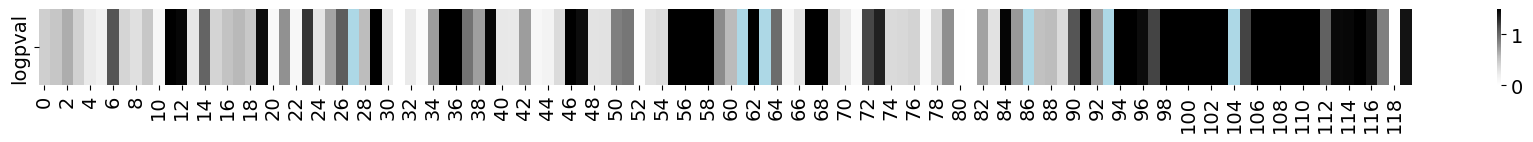

In [4]:
fig, ax = plt.subplots(1, figsize=(22,1))

ax=sns.heatmap(epi_genes[['logpval']].T, vmin=0, vmax=1.5, cmap='Greys')
plt.gca().set_facecolor('lightblue')
fig.savefig(f"{fig_dir}/matrixplot_cancer_celltype2_genes_heatmap_km_pvals.pdf")


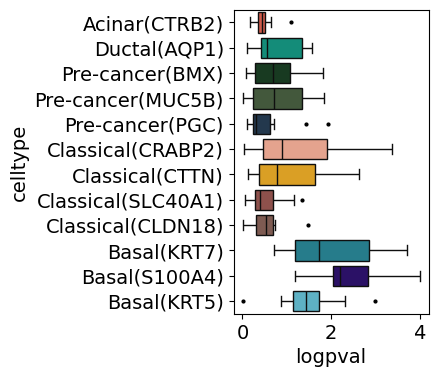

In [5]:
fig, ax = plt.subplots(1, 1, figsize=(2.5, 4))

flierprops = dict(marker='o', markerfacecolor='black', markersize=2,  markeredgecolor='black')
sns.boxplot(data=epi_genes, y='celltype', x='logpval', flierprops=flierprops,
            fliersize=2, palette=plate_level_all, ax=ax)
fig.savefig(f"{fig_dir}/cancer_celltype2_genes_heatmap_km.pdf", bbox_inches="tight")


In [214]:
group_normal = epi_genes[epi_genes.celltype.isin(['Acinar(CTRB2)','Ductal(AQP1)'])].logpval.tolist()

for i in epi_genes.celltype.unique():
    group_cancer = epi_genes[epi_genes.celltype.isin([i])].logpval.tolist()
    res_greater = stats.mannwhitneyu(group_normal, group_cancer, alternative='less', nan_policy='omit')
    print(f"Greater {i} p-value:", res_greater.pvalue)



Greater Acinar(CTRB2) p-value: 0.7795739705029693
Greater Ductal(AQP1) p-value: 0.23370119259243943
Greater Pre-cancer(BMX) p-value: 0.3271363954043074
Greater Pre-cancer(MUC5B) p-value: 0.3706888592578213
Greater Pre-cancer(PGC) p-value: 0.8868296032869251
Greater Classical(CRABP2) p-value: 0.07638586932873932
Greater Classical(CTTN) p-value: 0.20461406548363073
Greater Classical(SLC40A1) p-value: 0.8781613522082167
Greater Classical(CLDN18) p-value: 0.6203548708368114
Greater Basal(KRT7) p-value: 0.00015533017131959503
Greater Basal(S100A4) p-value: 2.782813998069949e-05
Greater Basal(KRT5) p-value: 0.0038879904597406358


### mes

In [218]:
mes_genes = pd.read_csv("/home/xuquan/projects/pdac/revision2/mes_km_50_purity.txt", sep='\t')
categories_order = ['Stellate(MACM)', 'Pre-CAF(TAGLN2)',
                    'csCAF(C7)', 'csCAF(CFH)', 'myCAF(HOPX)',
                    'myCAF(MMP11)', 'apCAF(CD74)', 'iCAF(EMP1)', 'iCAF(SOD2)']
mes_genes['celltype'] = [item for item in categories_order for _ in range(10)]
mes_genes.loc[mes_genes.logpval>4, 'logpval']=4

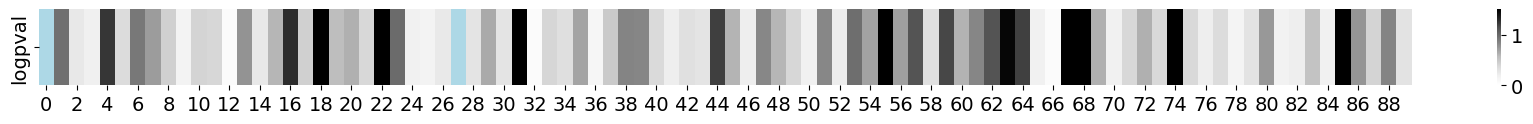

In [219]:
fig, ax = plt.subplots(1, figsize=(22,1))

ax=sns.heatmap(mes_genes[['logpval']].T, vmin=0, vmax=1.5, cmap='Greys')
plt.gca().set_facecolor('lightblue')
fig.savefig(f"{fig_dir}/matrixplot_caf_celltype2_genes_heatmap_km_pvals.pdf")


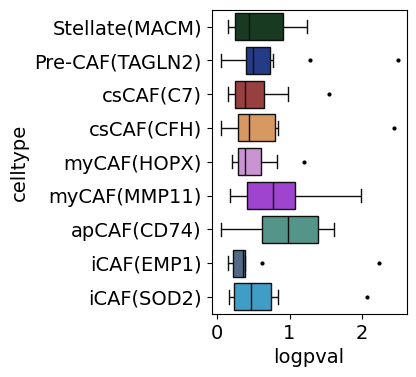

In [220]:
fig, ax = plt.subplots(1, 1, figsize=(2.5, 4))

sns.boxplot(data=mes_genes, y='celltype', x='logpval', flierprops=flierprops,
            fliersize=2, palette=plate_level_all, ax=ax)
fig.savefig(f"{fig_dir}/caf_celltype2_genes_heatmap_km.pdf", bbox_inches="tight")


In [221]:
group_normal = mes_genes[mes_genes.celltype.isin(['Stellate(MACM)'])].logpval.tolist()

for i in mes_genes.celltype.unique():
    group_cancer = mes_genes[mes_genes.celltype.isin([i])].logpval.tolist()
    res_greater = stats.mannwhitneyu(group_normal, group_cancer, alternative='less', nan_policy='omit')
    print(f"Greater {i} p-value:", res_greater.pvalue)



Greater Stellate(MACM) p-value: 0.5176903023184769
Greater Pre-CAF(TAGLN2) p-value: 0.38742955875744095
Greater csCAF(C7) p-value: 0.6044592435396092
Greater csCAF(CFH) p-value: 0.6433484130607712
Greater myCAF(HOPX) p-value: 0.6124743131649588
Greater myCAF(MMP11) p-value: 0.218971411449987
Greater apCAF(CD74) p-value: 0.11822235778615192
Greater iCAF(EMP1) p-value: 0.8043663603586804
Greater iCAF(SOD2) p-value: 0.5808717568070869


In [222]:
mes_genes.groupby(['celltype']).mean(numeric_only=True)

,pval,logpval
celltype,,
Pre-CAF(TAGLN2),0.336675,0.724037
Stellate(MACM),0.354583,0.579995
apCAF(CD74),0.239930,0.919770
csCAF(C7),0.384627,0.560181
csCAF(CFH),0.386748,0.646050
iCAF(EMP1),0.444753,0.517245
iCAF(SOD2),0.366213,0.619970
myCAF(HOPX),0.380507,0.499972
myCAF(MMP11),0.256816,0.817942


In [65]:
group_cancer

[1.94005294541913,
 0.095607855661116,
 0.0391955704867837,
 0.169821649884675,
 0.254927858046797,
 2.71446602451389,
 0.482650284698038,
 0.203188742240201,
 0.708041656742175,
 0.527332896586411]